<a href="https://colab.research.google.com/github/HaiderCaballero/Estadistica1_Tarea_2/blob/main/Tarea_2_Estad%C3%ADstica_descriptiva_para_variables_cuantitativas_en_lenguaje_Python.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **TAREA 2: ESTADÍSTICA DESCRIPTIVA PARA VARIABLES CUANTITATIVAS EN LENGUAJE PYTHON**

# **Estadística descriptiva para variables cuantitativas**

*  Gráficos estadísticos.
*  Supuesto de normalidad de la variable aleatoria: shapiro.
*  Medidas descriptivas para datos univariados.
*  Diagrama de dispersión.
*  Coeficientes de correlación de Pearson, de Kendall y de Spearman.

**INTEGRANTES:**

1.   MARIA PAULA ANAYA PARRA - 2251445.
2.   AARON JOEL RUEDA ARIZA - 2250766.
3.   HAIDER DANIEL CABALLERO ROJAS - 2251827.
4.   JOSE BENICIO VIVEROS BELTRAN - 2250783.

**PROFESOR:**
* ANDRES SEBASTIAN RIOS GUTIERREZ.

**Curso:** Estadistica I - **Grupo:** F1.


# **INTRODUCCION**

La siguiente tarea expone los resultados del análisis estadístico descriptivo realizado sobre la base de datos BD-EEVV-Nacimientos-2024, proporcionada por el Departamento Administrativo Nacional de Estadística (DANE). Esta base de datos recopila la información oficial de los certificados de nacimientos en Colombia. El objetivo principal es caracterizar y evaluar el comportamiento de dos variables específicas:
1. La edad del padre del recién nacido (EDAD_PADRE).
2. El número de embarazos de la madre (N_EMB).


Asimismo, se realiza un análisis univariado apoyado en gráficos estadísticos y medidas descriptivas, evaluando si estas variables siguen una distribución normal mediante la prueba de Shapiro. Finalmente, se examina la relación conjunta entre ambas variables mediante un diagrama de dispersión y el cálculo de los coeficientes de correlación de Pearson, Kendall y Spearman.

In [ ]:
from google.colab import files # Para cargar archivos en google colab
uploaded = files.upload() # Se tiene que establecer que la función es del módulo files

Saving BD-EEVV-Nacimientos-2024.csv to BD-EEVV-Nacimientos-2024.csv


In [ ]:
#Para decirle a python que archivo tenemos
import pandas as pd
import io
io_csv = io.BytesIO(uploaded['BD-EEVV-Nacimientos-2024.csv'])
tabla = pd.read_csv(io_csv, sep = ",", index_col=0, encoding='latin-1')
tabla.head(4)

,COD_MUNIC,AREANAC,SIT_PARTO,OTRO_SIT,SEXO,PESO_NAC,TALLA_NAC,ANO,MES,ATEN_PAR,...,N_HIJOSV,FECHA_NACM,N_EMB,SEG_SOCIAL,IDCLASADMI,EDAD_PADRE,NIV_EDUP,ULTCURPAD,PROFESION,TIPOFORMULARIO
COD_DPTO,,,,,,,,,,,,,,,,,,,,,
76,1,1,1,NaN,2,6,5,2024,5,1,...,2,21/09/2017,2,2,2.0,39,4,11,1.0,1
19,473,3,2,NaN,1,7,4,2024,6,5,...,3,27/06/2023,3,2,2.0,27,3,9,1.0,1
41,298,1,1,NaN,1,6,5,2024,4,1,...,3,23/06/2020,3,2,2.0,28,4,11,1.0,1
50,573,1,1,NaN,2,7,5,2024,5,1,...,1,NaN,1,2,2.0,27,3,7,1.0,1


In [ ]:
df = tabla[["EDAD_PADRE", "EDAD_MADRE", "N_EMB"]]
df.head(4)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1


# **GRÁFICOS ESTADÍSTICOS**


PREGUNTA 1:

**¿Cómo se comporta la variable aleatoria de la edad de un padre de un recién nacido en
Colombia (EDAD_PADRE)?**

Para dar respuesta a la pregunta, nos basaremos en el análisis de los siguientes gráficos estadísticos, que incluyen la interpretación en cada uno de ellos.


1. HISTOGRAMA


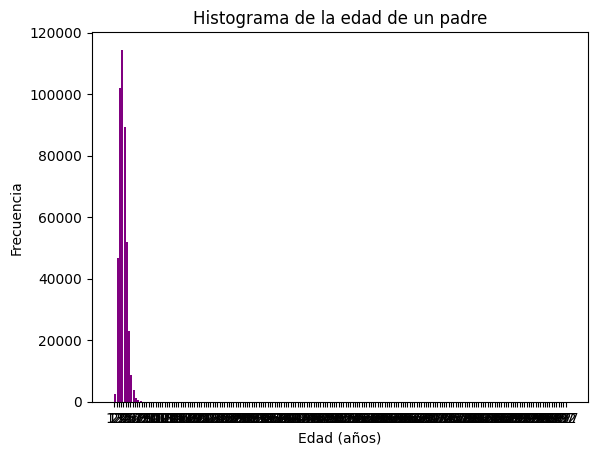

In [ ]:
import matplotlib.pyplot as plot
intervalos = range(min(df.EDAD_PADRE), max(df.EDAD_PADRE) +1, 5)

# Para construir el histograma
plot.hist(df.EDAD_PADRE, bins=intervalos, color='purple', rwidth=0.85)
plot.title("Histograma de la edad de un padre")
plot.xlabel("Edad (años)")
plot.ylabel("Frecuencia")
plot.xticks(intervalos)
plot.show()

In [ ]:
# Es necesario eliminar valores no representativoS (mayores a 100) debido a datos faltantes o errores de registro.

df1 = df[(df.EDAD_PADRE < 120) & (df.EDAD_MADRE !=99) & (df.N_EMB !=99)]
df.head(5)

,EDAD_PADRE,EDAD_MADRE,N_EMB
COD_DPTO,,,
76,39,6,2
19,27,4,3
41,28,4,3
50,27,2,1
50,31,4,5


/tmp/ipykernel_2120/475483119.py:19: UserWarning: color is redundantly defined by the 'color' keyword argument and the fmt string "k" (-> color=(0.0, 0.0, 0.0, 1)). The keyword argument will take precedence.
  plt.plot(x, p, 'k', linewidth=2, label='Distribución normal', color="darkgreen")


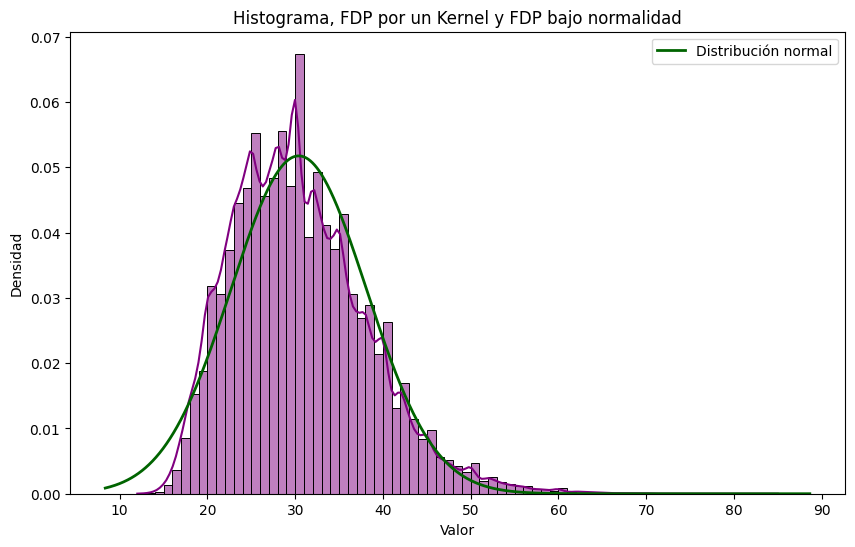

In [ ]:
# HISTOGRAMA
import seaborn as sns
import numpy as np # Para poder usar linspace
from scipy.stats import norm # Para poder usar la función de densidad de probabilidad de la distribución normal
import matplotlib.pyplot as plt

# Calculamos los extremos de los intervalos
intervalos1 = range (min(df1.EDAD_PADRE), max(df1.EDAD_PADRE)+1)
plt.figure(figsize=(10, 6))

#Kde = True: define la gráfica de densidad de probabilidad estimada por un método Kernel
sns.histplot(x = df1.EDAD_PADRE, bins=intervalos1, kde=True, stat = "density", color='purple', edgecolor="black")

# Para comparar la gráfica con la función de densidad de probabilidad de la distribución normal
xmin, xmax = plt.xlim()
x = np.linspace(xmin, xmax, 1000)
p = norm.pdf(x, np.mean(df1.EDAD_PADRE), np.std(df1.EDAD_PADRE))

plt.plot(x, p, 'k', linewidth=2, label='Distribución normal', color="darkgreen")

# Para añadir detalles finales
plt.title('Histograma, FDP por un Kernel y FDP bajo normalidad')
plt.xlabel('Valor')
plt.ylabel('Densidad')
plt.legend()

# Para mostrar el gráfico
plt.show()

Al comparar la distribución empírica de la variable $X:=$ "Edad del padre" por el método Kernel (Línea morada) no coindide con la función de densidad de probabilidad bajo normalidad (Linea verde oscura). La estimación por el método de Kernel revela un pico mucho más alto alrededor de los 30 años que la otra curva; esto significa que hay una concentración de datos en las edades (25-35 años) mayor que la que predice la distribución normal teórica.

$X\sim \text{Normal} (\text{Media} = \bar{x}, \text{Varianza} = S^2_x)$.

Por lo tanto, no asumimos normalidad; se refleja un comportamiento sesgado hacia la adultez joven del país.

# **Supuesto de normalidad de la variable aleatoria: Shapiro.**

El supuesto de normalidad Shapiro es utilizado para contrastar la normalidad de un conjunto de datos y se plantea como hipótesis nula que una muestra proviene de una población normalmente distribuida.

In [ ]:
from scipy.stats import shapiro
shapiro(df1. EDAD_PADRE)

ShapiroResult(statistic=np.float64(0.9677117198585043), pvalue=np.float64(7.6156069148173195e-109))

Tenemos que **pvalue=np.float64(7.6156069148173195e-109)) < 0.05** , es decir, se rechaza que la variable aleatoria $X:=$ "Edad del padre" presenta distribución normal.

In [ ]:
df1.EDAD_PADRE.count()
len(df1.EDAD_PADRE)

443777

In [ ]:
idx = np.random.randint(len(df1.EDAD_PADRE), size = 100)
idx
shapiro(df1.EDAD_PADRE.index[idx])

ShapiroResult(statistic=np.float64(0.8448323854567097), pvalue=np.float64(7.67652371580583e-09))

Como: **pvalue=np.float64 $(7.67652371580583 \times 10^{-9}$) < 0.05**, se confirma que, con un p-value tan pequeño, la variable $X:=$ "Edad del padre" no presenta distribución normal.

<Axes: ylabel='EDAD_PADRE'>

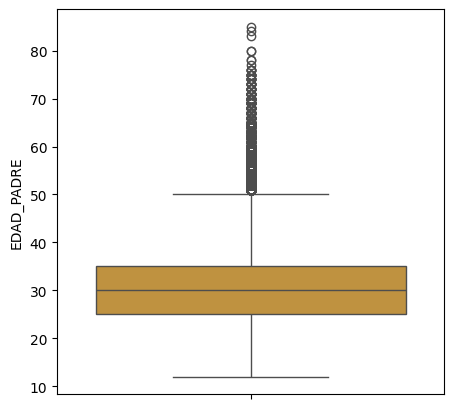

In [ ]:
# DIAGRAMA DE CAJAS Y BIGOTES
import seaborn as sns
plt.figure(figsize=(5, 5))
sns.boxplot(df1.EDAD_PADRE, color='Orange', saturation=0.50)

De la gráfica estadística se puede observar que la variable aleatoria de la edad de un padre presenta valores atípicos cuando es mayor a 50 años. Así, el primer cuartil de aproximadamente 25 años, la media aritmética se ubica en casi los 29 años y el tercer cuartil es aproximadamente 35 años.

$\text{Rango intercuartílico = Tercer cuartil - Primer cuartil} = 35 - 25 = 10$

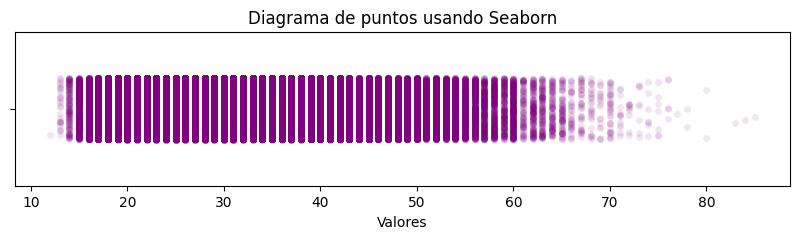

In [ ]:
# DIAGRAMA DE PUNTOS UNIDIMENSIONAL
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(10, 2))
sns.stripplot(x=df1.EDAD_PADRE, color='purple', alpha=0.1, jitter=0.2)
plt.title("Diagrama de puntos usando Seaborn")
plt.xlabel("Valores")
plt.show()


De acuerdo con el diagrama, se observa una alta variabilidad de la edad de un padre. Se interpreta cómo la densidad de puntos empieza a dispersarse después de los 50 años  y a medida que se acerca a los 70 años se vuelve un poco más separada o escasa.

# **Medidas Descriptivas**

In [ ]:
import numpy as np
# Importamos "snew" para calcular los coeficientes de asimetría y "kurtosis" para calcular la curtosis
from scipy.stats import skew, kurtosis
print(f"La Media aritmética es: {np.mean(df1.EDAD_PADRE)}")
print(f"La Varianza es: {np.var(df1.EDAD_PADRE)} y la desviación estándar es de: {np.std(df1.EDAD_PADRE)}")
print(f"El coeficiente de Asimetría es: {skew(df1.EDAD_PADRE)}")
print(f"La Curtosis es: {kurtosis(df1.EDAD_PADRE)}")


La Media aritmética es: 30.399666949841926
La Varianza es: 59.42512313787833 y la desviación estándar es de: 7.708769236258037
El coeficiente de Asimetría es: 0.7422600985923384
La Curtosis es: 0.8607555699997431


* Aproximadamente el promedio de la edad de un padre de un recién nacido en Colombia es de **30.4 años**.
*   La distancia entre los valores de la edad de un padre de un recién nacido en Colombia y la media es de aproximadamente **7.7 años**.
*   La distribución de la edad de un padre de un recién nacido en Colombia es asimétrica positiva, es decir, la media es mayor que la moda de la variable aleatoria.
*   La curtosis nos indica que la distribución es platicúrtica; es decir, existe una baja concentración de las edades de un padre de un recién nacido en Colombia con respecto a la media aritmética.

PREGUNTA 2.
**¿Cómo se comporta la variable aleatoria del número de embarazos incluido el presente
(N_EMB)?**

# **Diagrama de dispersión (Estadística descriptiva para datos bivariados)**


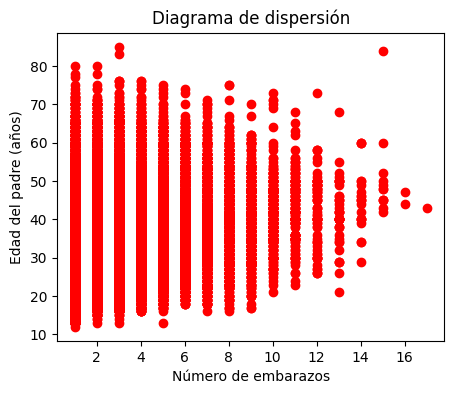

In [ ]:
# DIAGRAMA DE DISPERSION
plt.figure(figsize=(5, 4))
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color= "red", marker = "o")
plt.title("Diagrama de dispersión")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (años)")
plt.show()

En el diagrama de dispersión se observa una alta concentración de datos en los primeros valores de los embarazos. Aunque la nube de puntos es amplia, se puede decir que  las variables de la cantidad de embarazos y la edad de un padre estarían relacionadas.

In [ ]:
# RECTA DE REGRESION

#Se implementa un modelo de regresión lineal simple en Python
from sklearn.linear_model import LinearRegression
modelo = LinearRegression()
modelo.fit(np.array(df1.N_EMB).reshape(-1, 1), np.array(df1.EDAD_PADRE).reshape(-1, 1))

# Se hacen las predicciones del modelo lineal
predi_lineal = modelo.predict(np.array(df1.N_EMB).reshape(-1, 1))
predi_lineal

array([[30.31494332],
       [32.35070055],
       [32.35070055],
       ...,
       [30.31494332],
       [28.27918608],
       [30.31494332]])

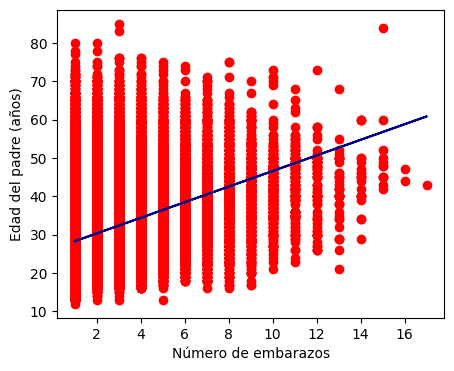

In [ ]:
plt.figure(figsize=(5, 4))
plt.scatter(df1["N_EMB"], df1["EDAD_PADRE"], color= "red", marker = "o")
plt.plot(df1.N_EMB, predi_lineal, linestyle="-", color = "darkblue")
plt.xlabel("Número de embarazos")
plt.ylabel("Edad del padre (años)")
plt.show()

Al trazar la recta de regresión lineal se evidencia una pendiente positiva. Esto indica una correlación positiva: a medida que aumenta la cantidad de embarazos registrados, la edad del padre promedio del padre tiende a ser mayor (la mayor concentración está entre los 25 y los 50 años). Sin embargo, la gran dispersión evidencia que la variable del número de embarazos no determina totalmente la edad del padre.


PREGUNTA 3

**¿Las variables están correlacionadas y qué grado de correlación tienen?**

# **Coeficientes de correlación de Pearson, de Kendall y de Spearman**

In [ ]:
# Grado de correlación o grado de dependencia
import numpy as np
from scipy.stats import spearmanr
from scipy.stats import kendalltau
coef_pearson = np.corrcoef(df1. N_EMB, df1.EDAD_PADRE)[0, 1]
coef_spearman, _ = spearmanr(df1. N_EMB, df1.EDAD_PADRE)
coef_kendall, _ = kendalltau(df1. N_EMB, df1.EDAD_PADRE)
print(f"El coeficiente de correlación de Pearson es: {coef_pearson}")
print(f"El coeficiente de correlación de Spearman es: {coef_spearman}")
print(f"El coeficiente de correlación de Kendall es: {coef_kendall}")

Para la interpretación de los coeficientes de correlación nos ayudaremos de la referencia:

Landis, J. R., & Koch, G. G. (1977). The measurement of observer agreement for categorical data. biometrics, 159-174. [Link] (https://www.jstor.org/stable/pdf/2529310.pdf)

Los coeficientes de correlación trabajados están dentro de un rango de [-1,1], siendo los valores extremos los que indican una alta dependencia de Y sobre X, y siendo 0 el que representa la nula correlación entre las variables.

De esta manera, se tiene que:

* X y Y son independientes o no están correlacionadas: $\rho (X,Y) \approx 0, \eta (X,Y) \approx 0, \kappa (X,Y) \approx 0$.
* Y depende insignificantemente de X o X y Y están insignificantemente correlacionadas si $0 < \vert \rho (X,Y) \vert < 0.2$, $0 < \vert \eta (X,Y) \vert < 0.2$, $0 < \vert \kappa (X,Y) \vert < 0.2$.
* Y depende discretamente de X o X y Y están discretamente correlacionadas si $0.2 < \vert \rho (X,Y) \vert < 0.4$, $0.2 < \vert \eta (X,Y) \vert < 0.4$, $0.2 < \vert \kappa (X,Y) \vert < 0.4$.
* Y depende moderadamente de X o X y Y están moderadamente correlacionadas si $0.4 < \vert \rho (X,Y) \vert < 0.6$, $0.4 < \vert \eta (X,Y) \vert < 0.6$, $0.4 < \vert \kappa (X,Y) \vert < 0.6$.
* Y depende sustancialmente de X o X y Y están sustancialmente correlacionadas si $0.6 < \vert \rho (X,Y) \vert < 0.8$, $0.6 < \vert \eta (X,Y) \vert < 0.8$, $0.6 < \vert \kappa (X,Y) \vert < 0.8$.
* Y depende fuertemente de X o X y Y están fuertemente correlacionadas si $0.8 < \vert \rho (X,Y) \vert < 1$, $0.8 < \vert \eta (X,Y) \vert < 1$, $0.8 < \vert \kappa (X,Y) \vert < 1$.

De acuerdo con los coeficientes de correlación, se interpreta que:


*  El número de embarazos y la edad de un padre de un recién nacido en Colombia están discretamente correlacionados; esto debido a que se encuentran en el rango de [0.2, 0.4].




# **CONCLUSIONES**

A partir del análisis realizado sobre la base de datos BD-EEVV-Nacimientos-2024 del DANE, se concluye que la variable EDAD_PADRE no sigue una distribución normal. Esto fue evidenciado mediante la estimación de densidad Kernel y  matemáticamente probado por la prueba de Shapiro con un p-valor significativamente menor a 0.05. Las medidas descriptivas muestran que la edad promedio de los padres en Colombia es de 30.4 años, con una desviación estándar de 7.7 años y una concentración central entre los 25 y 35 años, identificándose valores atípicos severos después de los 50 años.

Finalmente, el análisis bivariado y el cálculo de los coeficientes de correlación de Pearson, Spearman y Kendall demostraron que existe una relación positiva discreta entre el número de embarazos de la madre (N_EMB) y la edad del padre (EDAD_PADRE), situándose en el rango de [0.2, 0.4], lo que indica estadísticamente que un mayor número de embarazos en el registro tiende a asociarse con una mayor edad del progenitor.
